# Solutions

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## Polynomial fitting with SVD

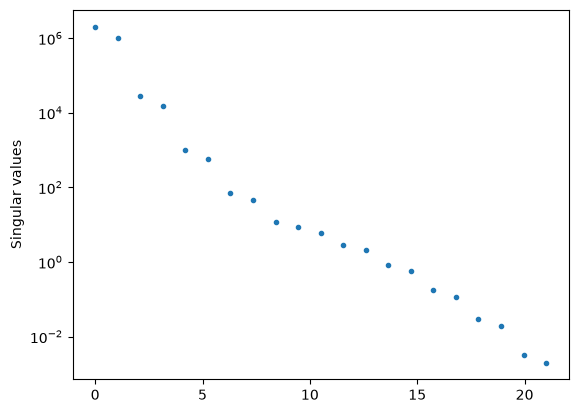

Range of singular values = 1.02088e+09
np.linalg.cond gives 1.02088e+09
Polynomial order, Polynomial coeffs, Fitted coeffs, Fractional error
x^0      0.770379      0.770379  -2.78414e-11
x^1     -0.467723     -0.467723  -1.27431e-10
x^2     -0.965288     -0.965288  -8.26157e-10
x^3     -0.747294     -0.747294   1.09002e-09
x^4     -0.440204     -0.440204   1.46649e-08
x^5       -0.7445       -0.7445  -3.28969e-09
x^6      0.237287      0.237287   8.46645e-08
x^7      0.173515      0.173515  -1.81156e-08
x^8      -0.60129      -0.60129   5.32493e-08
x^9      0.457022      0.457022   4.59554e-09
x^10     -0.649509     -0.649509  -4.55343e-08
x^11      0.481771      0.481771  -1.70295e-09
x^12     -0.587271     -0.587271     2.852e-08
x^13      0.618501      0.618501   3.49655e-10
x^14      0.599351      0.599351    9.8488e-09
x^15      0.892222      0.892222  -5.03207e-11
x^16     -0.917279     -0.917279   1.37639e-09
x^17      0.557765      0.557765   1.22037e-11
x^18     -0.558992     

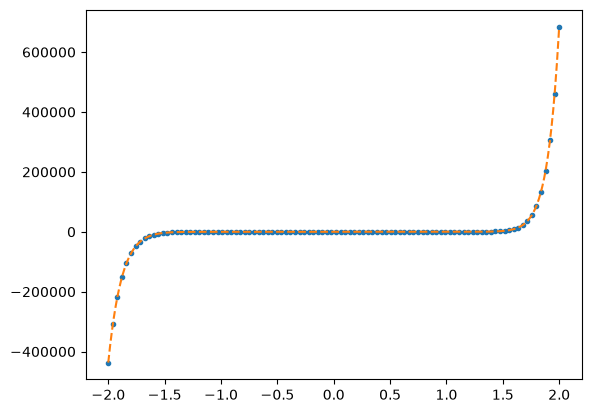

In [2]:
# first generate some data from a random polynomial

k = 20 # order of polynomial
n = 100  # number of data points
sigma = 0 # noise
useSVD = True

x = np.linspace(-2,2,n)
# generate random coefficients, each between -1 and 1
a0 = -1.0 + 2*np.random.rand(k+1)
# generate the polynomial and add some noise
poly = np.polynomial.Polynomial(a0)
y = poly(x) + np.random.normal(scale=sigma, size=n)

# Compute the design matrix
# A_{ij} = f_j(x_i)
A = np.zeros((n, k+1))
for kk in range(k+1):
    A[:, kk] = x**kk
# We could also use:
# A = np.vander(x, N=k+1, increasing=True)

# SVD
U, Sdiag, VT = np.linalg.svd(A,full_matrices=False)

# plot the singular values
plt.clf()
plt.plot(np.linspace(0,len(Sdiag),len(Sdiag)),Sdiag,'.')
plt.yscale('log')
plt.ylabel(r'Singular values')
plt.show()
    
print("Range of singular values = %g" % (max(abs(Sdiag))/min(abs(Sdiag))))
print("np.linalg.cond gives %g" % (np.linalg.cond(A)))

# Now do the linear algebra part
if useSVD:
    a = VT.T @ np.diag(1/Sdiag) @ (U.T @ y)
    # Note: the ordering makes a difference-if you remove
    # the brackets around U.T@y, this is more susceptible to round-off
else:
    rhs = np.transpose(A)@y
    lhs = np.transpose(A)@A
    a = np.linalg.inv(lhs)@rhs

print("Polynomial order, Polynomial coeffs, Fitted coeffs, Fractional error")
for i in range(k+1):
    print("x^%d %13g %13g %13g" % (i, a0[i], a[i], (a[i]-a0[i])/a0[i]))

# Plot the fitted polynomial on top of the original
plt.figure()
plt.plot(x,y,'.')
xx = np.linspace(-2,2,1000)
poly = np.polynomial.Polynomial(a)
yy = poly(xx)
plt.plot(xx,yy,'--')

if sigma>0.0:
    chi2 = np.mean((y-poly(x))**2)/sigma**2
else:
    chi2 = np.mean((y-poly(x))**2)
print('reduced chi2 = %g' % (chi2,))

plt.show()

## Orthogonal polynomials

In [3]:
# Visualize matrices as a color map
def plot_matrices(A,titles=[]):
    n = len(A)
    if titles==[]:
        titles = [""]*n
    if n>4:
        nx = 4
    else:
        nx = n
    for j in range(int(np.floor(n/4))+1):        
        plt.clf()
        plt.figure(figsize=(nx*4,4))
        jmax = 4*(j+1)
        if jmax > n:
            jmax = n
        for i,AA in enumerate(A[4*j:jmax]):
            plt.subplot(1, nx, i+1)
            plt.imshow(AA)
            plt.colorbar()
            plt.title(titles[4*j + i])
        plt.show()

In [4]:
# first generate some data from a random polynomial
k = 20  # order of polynomial
n = 100   # number of data points

kfit = 20  # number of basis functions for the fit

x = np.linspace(-2,2,n)
a0 = -1.0 + 2*np.random.rand(k+1)
poly = np.polynomial.Polynomial(a0)
y = poly(x) + np.random.normal(scale=0.0, size=n)

# OR try a more complicated function
#y = np.exp(np.sin(x**3)) + np.tanh(x)**3

In [5]:
def do_fit(A, y, use_svd = True):
    
    if use_svd:
        U, Sdiag, VT = np.linalg.svd(A,0)
        a = VT.T @ np.diag(1/Sdiag) @ U.T @ y
    else:
        rhs = np.transpose(A)@y
        lhs = np.transpose(A)@A
        a = np.linalg.inv(lhs)@rhs

    return a

<Figure size 640x480 with 0 Axes>

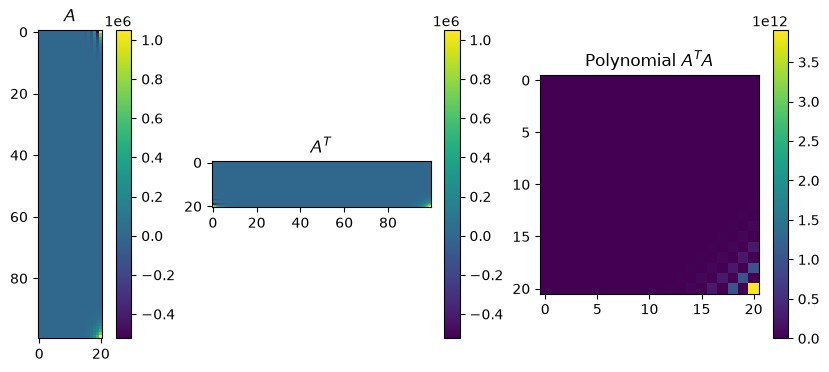

<Figure size 640x480 with 0 Axes>

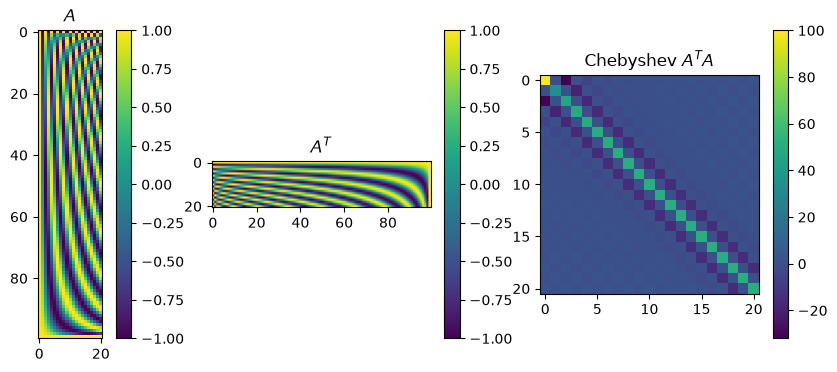

Condition number = 3.1319
Chebyshev coefficients:
a0 101679
a1 24113.3
a2 184054
a3 18813.6
a4 136239
a5 11373.4
a6 82045.7
a7 5246.63
a8 39809.1
a9 1795.94
a10 15317.3
a11 433.091
a12 4558.75
a13 65.7908
a14 1009.17
a15 4.33565
a16 155.742
a17 -0.257626
a18 14.8549
a19 -0.0465684
a20 0.652712
mean square deviation = 2.67565e-20


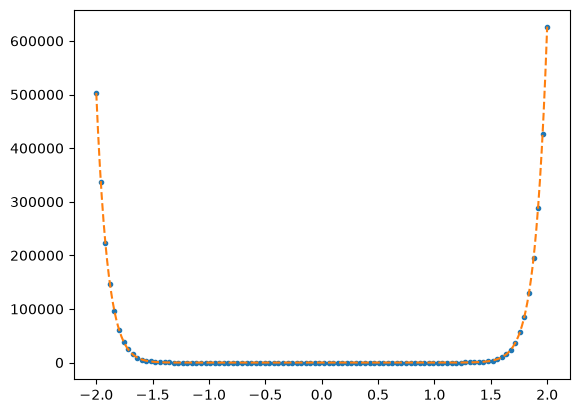

In [6]:
A = np.vander(x, N=kfit+1, increasing=True)
plot_matrices([A,A.T,A.T@A], titles=[r"$A$",r"$A^T$",r"Polynomial $A^TA$"])

# Fit with Chebyshev polynomials
A = np.polynomial.chebyshev.chebvander(x/2,kfit)

plot_matrices([A,A.T,A.T@A], titles=[r"$A$",r"$A^T$",r"Chebyshev $A^TA$"])

print("Condition number = %g" % (np.linalg.cond(A)))

a_cheb = do_fit(A, y)
      
print("Chebyshev coefficients:")
for i in range(len(a_cheb)):
    print("a%d %g" % (i, a_cheb[i]))

plt.figure()
plt.plot(x,y,'.')

xx = np.linspace(-2,2,1000)
poly_cheb = np.polynomial.Chebyshev(a_cheb)
yy = poly_cheb(xx/2)
plt.plot(xx,yy,'--')

chi2 = np.mean((y-poly_cheb(x/2))**2)
print('mean square deviation = %g' % (chi2,))
plt.show()

Condition number = 6.42377


<Figure size 640x480 with 0 Axes>

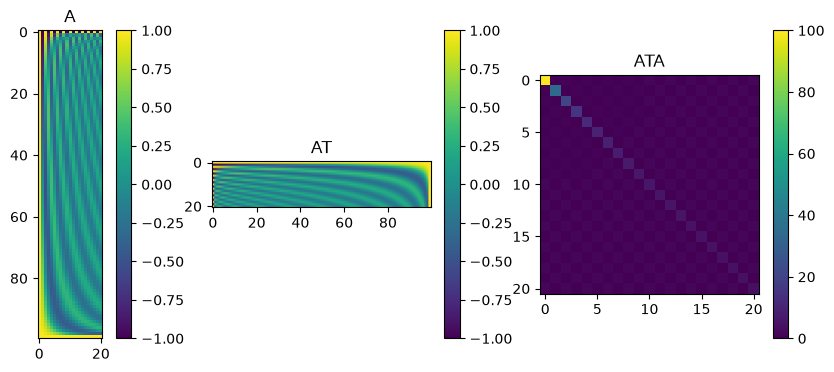

Legendre coefficients:
a0 28076.4
a1 10768.3
a2 121250
a3 18571.1
a4 154729
a5 16795.4
a6 129323
a7 10101.9
a8 79065.7
a9 4205.37
a10 36301.4
a11 1184.15
a12 12451.2
a13 205.139
a14 3100.73
a15 15.4865
a16 528.821
a17 -0.860288
a18 54.9754
a19 -0.18108
a20 2.60313
mean square deviation = 8.71972e-19


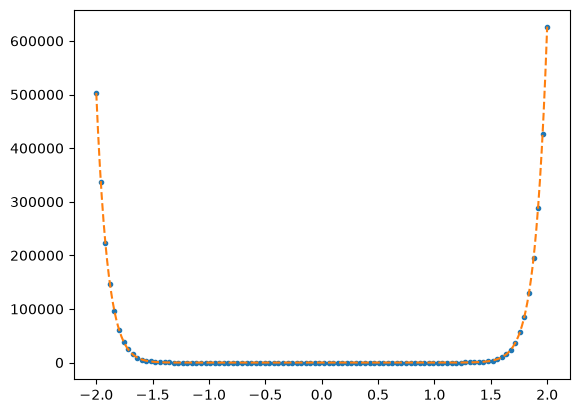

In [7]:
# Fit with Legendre polynomials
A = np.polynomial.legendre.legvander(x/2,kfit)

print("Condition number = %g" % (np.linalg.cond(A)))
plot_matrices([A,A.T,A.T@A], titles=["A","AT","ATA"])

a_leg = do_fit(A, y)
      
print("Legendre coefficients:")
for i in range(len(a_leg)):
    print("a%d %g" % (i, a_leg[i]))

plt.figure()
plt.plot(x,y,'.')

xx = np.linspace(-2,2,1000)
poly_leg = np.polynomial.Legendre(a_leg)
yy = poly_leg(xx/2)
plt.plot(xx,yy,'--')

chi2 = np.mean((y-poly_leg(x/2))**2)
print('mean square deviation = %g' % (chi2,))
plt.show()

## Lorentzian fit

In [8]:
def lorentz(a, x, finite_difference = False):
    # Calculates the Lorentz function and the derivative with respect to the parameters
    y = a[0] / (a[1] + (x-a[2])**2)
    A =  np.zeros([len(x), len(a)])
    if finite_difference:
        eps = 1e-8
        b = a * (1+eps)
        y0 = b[0] / (a[1] + (x-a[2])**2)
        y1 = a[0] / (b[1] + (x-a[2])**2)
        y2 = a[0] / (a[1] + (x-b[2])**2)
        A[:, 0] = (y0 - y) / (b[0]-a[0])
        A[:, 1] = (y1 - y) / (b[1]-a[1])
        A[:, 2] = (y2 - y) / (b[2]-a[2])
    else:
        A[:, 0] = 1 / (a[1] + (x-a[2])**2)
        A[:, 1] = - a[0] / (a[1] + (x-a[2])**2)**2
        A[:, 2] = 2 * a[0] * (x-a[2]) / (a[1] + (x-a[2])**2)**2
    return y, A

In [9]:
# Generate a set of "measurements" of a Lorentzian function
a0 = np.array((1.2, 2, 0.3))   # parameters of the Lorentzian
ndata = 100   # number of measurements 
x = np.linspace(-10, 10, ndata)
y, _ = lorentz(a0, x) 
y = y + 0.03 * np.random.normal(size = ndata)

In [10]:
# Initial guess for Newton's method
a = np.array((1,1,1))

# we have two options: analytic or numerical derivatives
finite_difference = True

# print the starting parameters and error
f, _ = lorentz(a, x, finite_difference=finite_difference)
r = y-f
last_chisq = 1e99
chisq = np.sum(r**2)
print("chisq = %g, a=(%lg, %lg, %lg)" % (chisq, a[0], a[1], a[2]))

# keep iterating while chi-squared drops by at least 1e-3
# note that this means we will also stop if chi-squared starts to increase
# which means we are not converging
while last_chisq - chisq > 1e-3:
    # calculate the update to the parameters
    f, A = lorentz(a, x, finite_difference=finite_difference)
    r = y-f
    lhs = A.T@A
    rhs = A.T@r
    da = np.linalg.inv(lhs)@rhs
    a = a + da
    # update the error
    last_chisq = chisq
    f, _ = lorentz(a, x, finite_difference=finite_difference)
    r = y-f
    chisq = np.sum(r**2)
    print("chisq = %g, a=(%lg, %lg, %lg)" % (chisq, a[0], a[1], a[2]))

print("a-a0 =", a-a0)

print("Best-fit parameters are: ", a)


chisq = 1.69126, a=(1, 1, 1)
chisq = 0.328141, a=(1.2648, 1.80249, 0.700053)
chisq = 0.085747, a=(1.31737, 2.1929, 0.36633)
chisq = 0.0774417, a=(1.20367, 1.94639, 0.293056)
chisq = 0.0774212, a=(1.2055, 1.95077, 0.297299)
a-a0 = [ 0.00549635 -0.0492311  -0.00270081]
Best-fit parameters are:  [1.20549635 1.9507689  0.29729919]


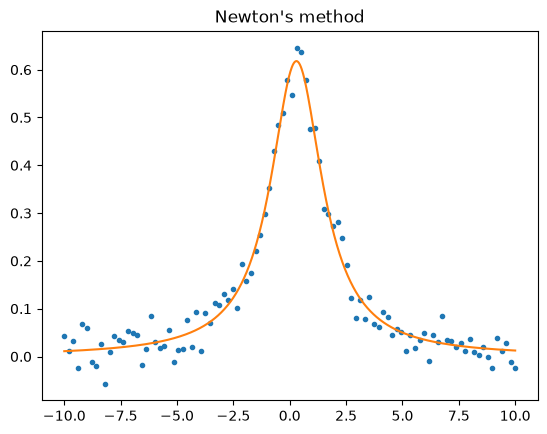

In [11]:
plt.plot(x, y, ".")

xx = np.linspace(-10, 10, 1000)
yy, _ = lorentz(a, xx)
plt.plot(xx,yy)
plt.title('Newton\'s method')

plt.show()

chisq = 4.37491, a=(1.04677, 2.11842, 3.84252), lam = 0.001
chisq = 2.5987, a=(2.383, 7.2037, 3.1474), lam = 0.0001
chisq = 1.26927, a=(5.81408, 22.2693, 0.290227), lam = 1e-05
chisq = 280.126, a=(-5.54224, -37.2157, 0.231855), lam = 1e-06
chisq = 266.149, a=(-5.5395, -37.2026, 0.231862), lam = 1e-05
chisq = 179.587, a=(-5.51216, -37.0721, 0.231936), lam = 0.0001
chisq = 4044.94, a=(-5.24547, -35.7993, 0.232654), lam = 0.001
chisq = 71.5155, a=(-3.11685, -25.6358, 0.238435), lam = 0.01
chisq = 1.39015, a=(3.00175, 3.74213, 0.256551), lam = 0.1
chisq = 1.10171, a=(5.74048, 18.3468, 0.275012), lam = 1
chisq = 0.435925, a=(3.03307, 6.16123, 0.282853), lam = 0.1
chisq = 0.411048, a=(0.830616, 0.93053, 0.296508), lam = 0.01
chisq = 0.118369, a=(1.04549, 1.47644, 0.299196), lam = 0.001
chisq = 0.0788502, a=(1.17822, 1.85758, 0.298365), lam = 0.0001
chisq = 0.0774237, a=(1.20446, 1.94692, 0.297452), lam = 1e-05
chisq = 0.0774212, a=(1.20544, 1.95065, 0.2973), lam = 1e-06
a-a0 = [ 0.00544324 -

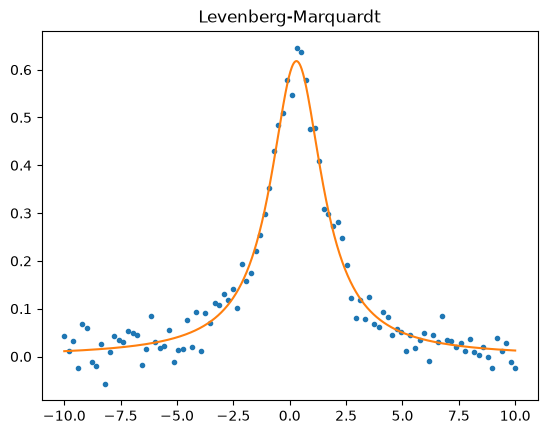

In [12]:
# Levenberg-Marquardt

# Note that this starting point doesn't converge for Newton!
a = np.array((1,1,4))

# we have two options: analytic or numerical derivatives
finite_difference = True

chisq1 = 1.0
chisq = 1e99
lam = 1e-3
# keep going while chisq is dropping
while chisq > 1e-6:
    # compute the update to the parameters
    f, A = lorentz(a, x, finite_difference=finite_difference)
    r = y-f
    chisq = np.sum(r**2)
    lhs = A.T@A
    lhs = lhs*(1 + np.identity(len(a))*lam)
    rhs = A.T@r
    da = np.linalg.inv(lhs)@rhs
    # calculate the chisq associated with the new parameters
    a1 = a + da
    f1, A1 = lorentz(a1, x, finite_difference=finite_difference)
    r1 = y-f1
    chisq1 = np.sum(r1**2)
    print("chisq = %lg, a=(%lg, %lg, %lg), lam = %lg" % (chisq1 ,a1[0], a1[1], a1[2], lam))
    # accept if chisq decreases; reject if it increases
    if chisq1 > chisq:
        lam = lam * 10
    else:
        lam = lam / 10
        a = a1
        # if the improvement in chisq becomes too small then exit
        if chisq-chisq1 < 1e-3:
            break
    
print("a-a0 =", a-a0)

print("Best-fit parameters are: ", a)

plt.plot(x, y, ".")

xx = np.linspace(-10, 10, 1000)
yy, _ = lorentz(a, xx)
plt.plot(xx,yy)
plt.title('Levenberg-Marquardt')

plt.show()

Best-fit parameters are:  [1.20544923 1.95066289 0.29729558]  chisq =  0.07742117950836006


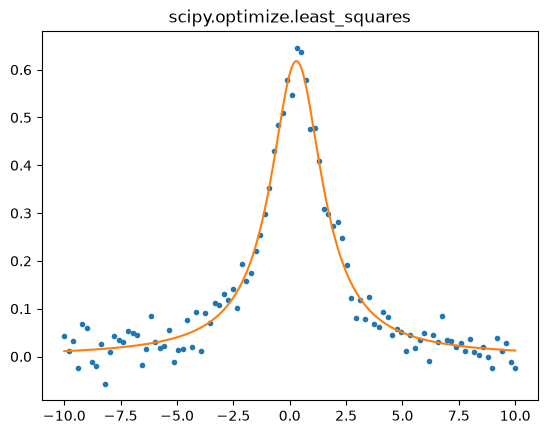

In [13]:
# Use the scipy least squares fitting routine to compare

import scipy.optimize

def res(a, x, y0):
    f = a[0] / (a[1] + (x-a[2])**2)
    return y-f

result = scipy.optimize.least_squares(res, (1,1,4), args=(x,y), method = 'lm')
print("Best-fit parameters are: ", result.x, " chisq = ", 2*result.cost)

plt.plot(x, y, ".")

xx = np.linspace(-10, 10, 1000)
yy, _ = lorentz(result.x, xx)
plt.plot(xx,yy)
plt.title('scipy.optimize.least_squares')

plt.show()